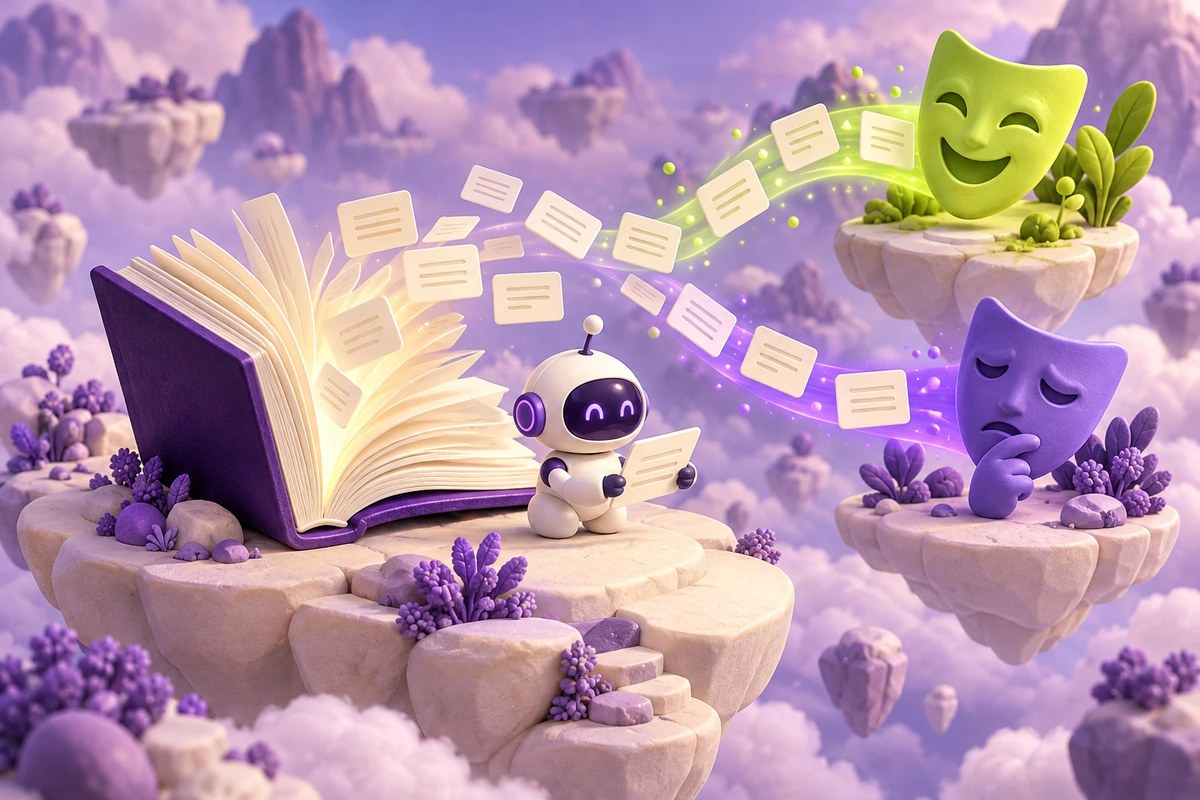

AI PATH · Нейросети для текста · Урок 027

# Тональность IMDb: память GRU

Последовательность из 200 токенов и компактное рекуррентное состояние.

**Архивный учебный материал.** Код и сохранённые результаты относятся к исходному ноутбуку. Оформление не означает новый запуск или подтверждение старых метрик. Перед выполнением проверьте зависимости и ограничения.

<a id="ai-027-goal"></a>
## Что вы разберёте

Понять, как GRU накапливает информацию об отзыве и как читать кривые обучения.

### Перед началом

- Embedding и последовательности
- Бинарная классификация в Keras

### Что понадобится

- TensorFlow/Keras, NumPy и Matplotlib
- Сетевой доступ к IMDb при первом load_data
- IPython/Colab; модель обучается 20 эпох в исходном варианте

## Навигация по уроку

- [Цель и подготовка](#ai-027-goal)
- [Карта урока](#ai-027-map)
- [Подготовка среды](#ai-027-section-01)
- [Отзывы и словарь](#ai-027-section-02)
- [Одинаковая длина](#ai-027-section-03)
- [Состояние GRU](#ai-027-section-04)
- [Кривые обучения](#ai-027-section-05)
- [Финальный тест](#ai-027-section-06)
- [Проверьте понимание](#ai-027-practice)
- [Источники и ограничения](#ai-027-provenance)

<a id="ai-027-map"></a>
## Карта урока

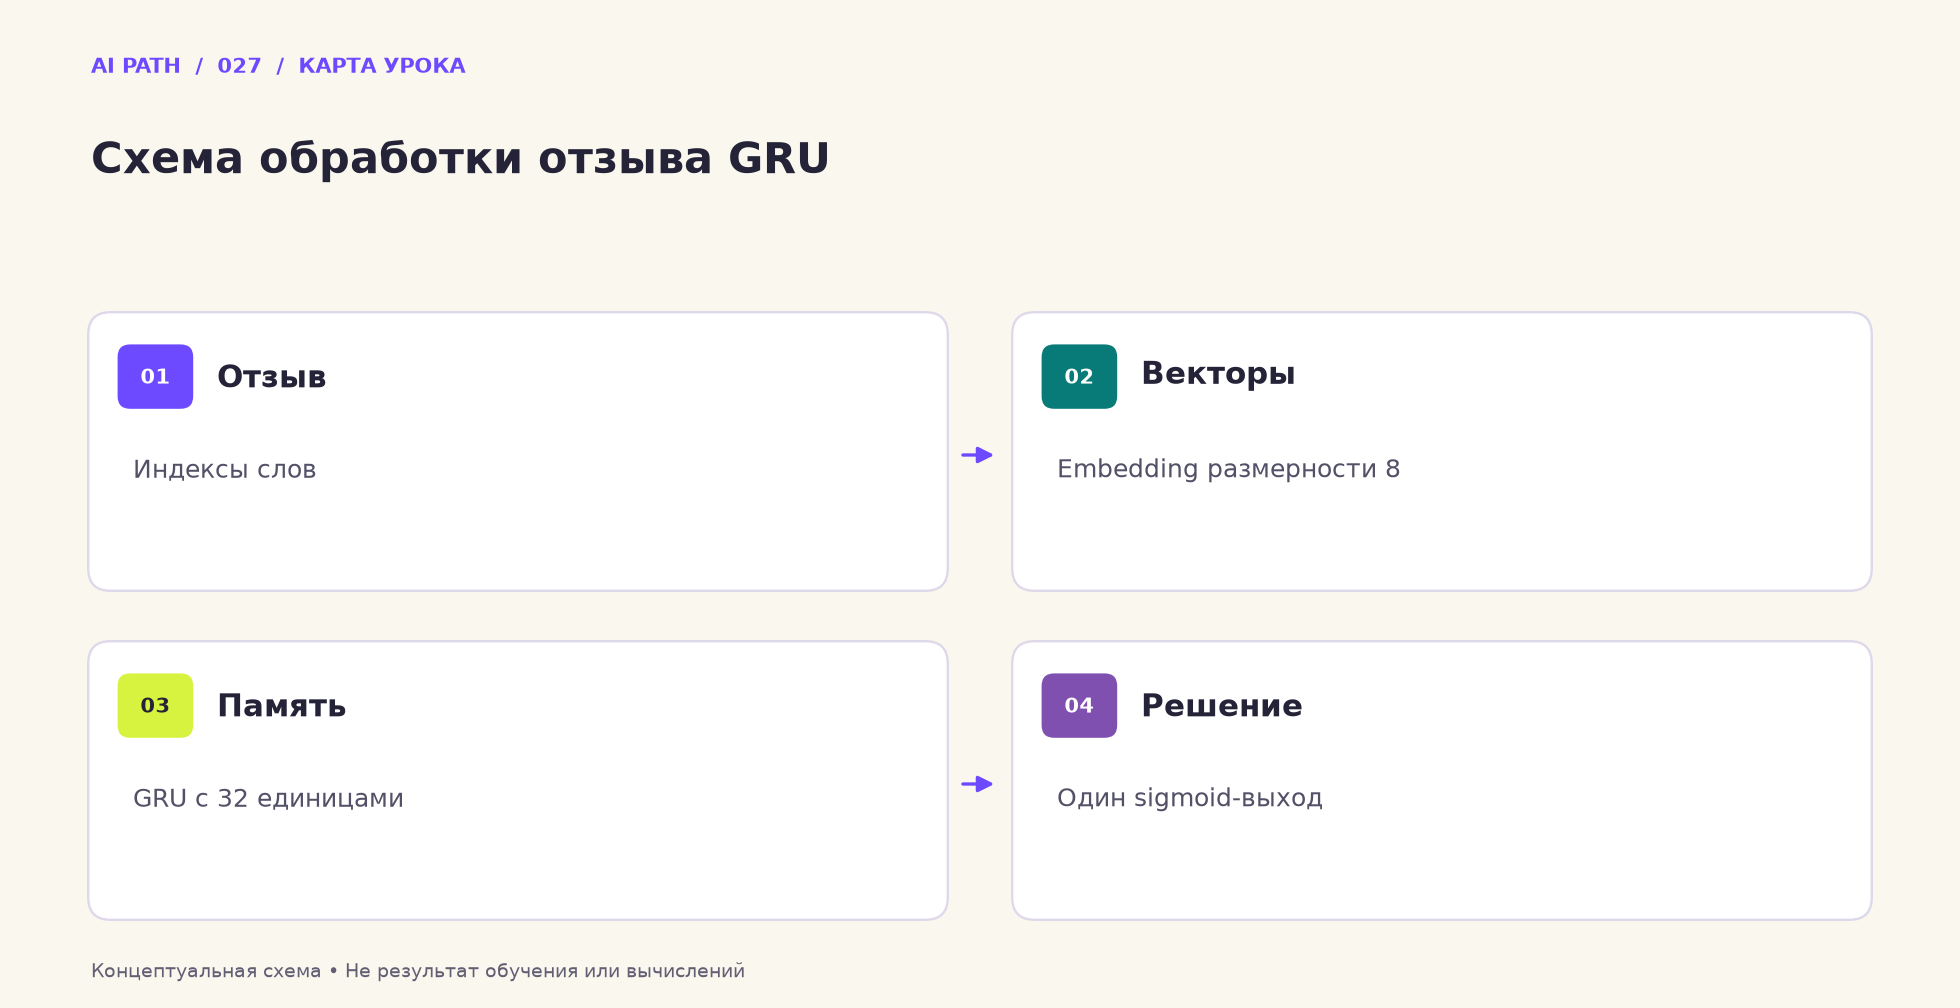

Схема показывает последовательность идей. Она не содержит результатов нового обучения или вычислений.

1. **Отзыв** — Индексы слов
2. **Векторы** — Embedding размерности 8
3. **Память** — GRU с 32 единицами
4. **Решение** — Один sigmoid-выход

<a href="https://colab.research.google.com/github/safal207/hello-world/blob/master/NLP_%D0%90%D0%BD%D0%B0%D0%BB%D0%B8%D0%B7_%D1%82%D0%BE%D0%BD%D0%B0%D0%BB%D1%8C%D0%BD%D0%BE%D1%81%D1%82%D0%B8_%D0%A0%D0%B5%D1%88%D0%B5%D0%BD%D0%B8%D0%B5_%D1%87%D0%B5%D1%80%D0%B5%D0%B7_Embedding_%2B_GRU(accuracy_0_83).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Определение тональности текста отзывов на фильмы IMDB с помощью сети GRU



Чтобы запускать и редактировать код, сохраните копию этого ноутбука себе (File->Save a copy in Drive...). Свою копию вы сможете изменять и запускать.

Не забудьте подключить GPU, чтобы сеть обучалась быстрее (Runtime -> Change Runtime Type -> Hardware Accelerator -> GPU).

<a id="ai-027-section-01"></a>
## 01 · Подготовка среды

Сверьте используемую версию TensorFlow с архивной командой Colab.

_Далее — исходные ячейки учебного материала._

In [ ]:
%tensorflow_version 2.x
from tensorflow.keras.datasets import imdb
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Embedding, GRU 
from tensorflow.keras import utils
from tensorflow.keras.preprocessing.sequence import pad_sequences
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline 

<a id="ai-027-section-02"></a>
## 02 · Отзывы и словарь

Набор загружается с ограничением словаря в 10 000 токенов.

_Далее — исходные ячейки учебного материала._

## Загружаем данные

In [ ]:
max_words=10000

In [ ]:
(x_train, y_train), (x_test, y_test) = imdb.load_data(num_words=max_words)

17465344/17464789 [==============================] - 0s 0us/step


<a id="ai-027-section-03"></a>
## 03 · Одинаковая длина

Проверьте дополнение нулями и обрезку до 200 позиций.

_Далее — исходные ячейки учебного материала._

## Подготовка данных для обучения

In [ ]:
maxlen = 200

In [ ]:
x_train = pad_sequences(x_train, maxlen=maxlen)
x_test = pad_sequences(x_test, maxlen=maxlen)

In [ ]:
x_train[5002]

array([   0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,
          0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,
          0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,
          0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,
          0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,
          0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,
          0,    0,    0,    1,  103,   51,   13,  197,   16,    6, 4796,
        239,    7,  107,  555,   11,  132,   39, 8921, 1872,  138,   16,
       4093, 1768, 2959,   34, 1620,    2,   11,    4,  755,   12,   43,
        286,    4,  172,  209,    2,    5, 5938,   17, 1000,   34, 1768,
        279,   29, 3892,   89,  338,    4,  114,   16, 1240, 1747,  103,
       3844, 3819,    8,  169, 2875,  112, 7062,   34,  160,  132,   29,
        100,   24,  535,  101,  250,    8,  858,   15,  196,   19,   57,
       3154,   39,   90,    5,   24,  169, 3533,   

<a id="ai-027-section-04"></a>
## 04 · Состояние GRU

Восемь координат Embedding поступают в GRU с 32 единицами состояния.

_Далее — исходные ячейки учебного материала._

## Создание нейронной сети

In [ ]:
model = Sequential()
model.add(Embedding(max_words, 8, input_length=maxlen))
model.add(GRU(32))
model.add(Dense(1, activation='sigmoid'))

In [ ]:
model.compile(optimizer='adam', 
              loss='binary_crossentropy', 
              metrics=['accuracy'])

<a id="ai-027-section-05"></a>
## 05 · Кривые обучения

Смотрите на расхождение обучения и проверки на протяжении 20 эпох.

_Далее — исходные ячейки учебного материала._

## Обучаем нейронную сеть

In [ ]:
history = model.fit(x_train, 
                    y_train, 
                    epochs=20,
                    batch_size=128,
                    validation_split=0.1)

Epoch 1/20
176/176 [==============================] - 3s 15ms/step - loss: 0.5248 - accuracy: 0.7147 - val_loss: 0.3370 - val_accuracy: 0.8636
Epoch 2/20
176/176 [==============================] - 2s 12ms/step - loss: 0.2740 - accuracy: 0.8919 - val_loss: 0.2980 - val_accuracy: 0.8832
Epoch 3/20
176/176 [==============================] - 2s 12ms/step - loss: 0.1983 - accuracy: 0.9256 - val_loss: 0.3097 - val_accuracy: 0.8752
Epoch 4/20
176/176 [==============================] - 2s 12ms/step - loss: 0.1625 - accuracy: 0.9408 - val_loss: 0.4242 - val_accuracy: 0.8384
Epoch 5/20
176/176 [==============================] - 2s 12ms/step - loss: 0.1351 - accuracy: 0.9537 - val_loss: 0.3518 - val_accuracy: 0.8636
Epoch 6/20
176/176 [==============================] - 2s 12ms/step - loss: 0.1144 - accuracy: 0.9634 - val_loss: 0.3904 - val_accuracy: 0.8684
Epoch 7/20
176/176 [==============================] - 2s 12ms/step - loss: 0.0955 - accuracy: 0.9694 - val_loss: 0.4442 - val_accuracy: 0.8536

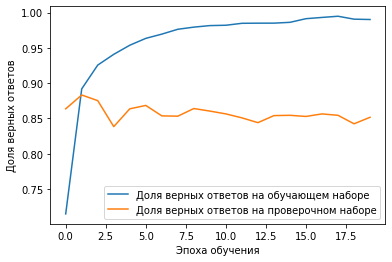

In [ ]:
plt.plot(history.history['accuracy'], 
         label='Доля верных ответов на обучающем наборе')
plt.plot(history.history['val_accuracy'], 
         label='Доля верных ответов на проверочном наборе')
plt.xlabel('Эпоха обучения')
plt.ylabel('Доля верных ответов')
plt.legend()
plt.show()

<a id="ai-027-section-06"></a>
## 06 · Финальный тест

Отдельный набор нужен для оценки выбранного варианта.

_Далее — исходные ячейки учебного материала._

## Проверяем работу сети на тестовом наборе данных

In [ ]:
scores = model.evaluate(x_test, y_test, verbose=1)

782/782 [==============================] - 4s 5ms/step - loss: 0.8286 - accuracy: 0.8316


<a id="ai-027-practice"></a>
## Проверьте понимание

1. Почему порядок токенов имеет значение для GRU?
2. Игнорирует ли эта Embedding нулевой padding автоматически?
3. На какой эпохе проверочная кривая перестаёт улучшаться?

### Один самостоятельный эксперимент

Сравните GRU с 16 и 32 единицами при одинаковых данных и числе эпох.

**Критерий успеха:** Сопоставлены число параметров и проверочная кривая без выбора по тесту.

<a id="ai-027-provenance"></a>
## Источники и ограничения

[Исходный ноутбук и его авторские материалы](https://github.com/safal207/students/blob/d848e04c8f8d6e3e8e42ce15fbd98c00612e0e17/NLP/NLP_%D0%90%D0%BD%D0%B0%D0%BB%D0%B8%D0%B7_%D1%82%D0%BE%D0%BD%D0%B0%D0%BB%D1%8C%D0%BD%D0%BE%D1%81%D1%82%D0%B8_%D0%A0%D0%B5%D1%88%D0%B5%D0%BD%D0%B8%D0%B5_%D1%87%D0%B5%D1%80%D0%B5%D0%B7_Embedding_%2B_GRU%28accuracy_0_83%29.ipynb) · репозиторий `safal207/students`.

Исходные подписи, ссылки, авторство, код, изображения и аудио сохранены. Длинные текстовые выводы могут быть сокращены с указанием источника. Архивные результаты не пересчитывались.

### Перед новым запуском

- В Embedding не задан mask_zero; заполнение нулями не объявлено маскируемым.
- Исходная команда %tensorflow_version устарела; совместимость API требует проверки.
- Загрузка IMDb и обучение не запускались; архивные значения не являются текущим результатом.

**Иллюстрации:** обложка направления AI PATH; карта урока подготовлена по содержимому исходных ячеек.